# Vision — OCR: Praproses Gambar + Evaluasi CER/WER (EasyOCR lokal)
**Kapan dipakai:** gambar teks miring, buram, berbintik, atau kontras rendah, dan hasil OCR
mentah banyak salah.

**Langkah:** perbesar → haluskan bintik → hitam-putih (threshold) → EasyOCR → bandingkan
CER/WER gambar mentah vs hasil praproses.
CER = huruf salah / jumlah huruf, WER = kata salah / jumlah kata (makin kecil makin baik).

**Data demo:** 240 baris teks SINTETIS (font acak). Kolom `gangguan` 0 / 0.4 / 0.8 = bersih /
sedang / berat. Kunci jawaban = kolom `teks`.

In [1]:
import cv2
import easyocr
import jiwer
import matplotlib.pyplot as plt
import pandas as pd
import torch

ModuleNotFoundError: No module named 'jiwer'

## Konfigurasi

In [2]:
DATA_FOLDER = "../../data_latihan/vision/ocr"   # GANTI saat lomba
LINES_CSV = f"{DATA_FOLDER}/baris.csv"
EASYOCR_FOLDER = "../../pretrained/easyocr"

LANGUAGES = ["en", "id"]
PATH_COL = "path"         # path gambar, relatif terhadap DATA_FOLDER
TEXT_COL = "teks"         # teks asli, hanya ada di data latihan
NOISE_COL = "gangguan"    # hanya ada di data demo

## Baca data

In [3]:
lines = pd.read_csv(LINES_CSV)
print(lines.shape)
print(lines[NOISE_COL].value_counts())
lines.head()

(240, 3)
gangguan
0.0    80
0.4    80
0.8    80
Name: count, dtype: int64


,path,teks,gangguan
0,baris/baris000.png,kelurahan mining bawang kartu Rp605.598,0.0
1,baris/baris001.png,medan bandung pagi 06/10/2023,0.4
2,baris/baris002.png,rumah nomor,0.8
3,baris/baris003.png,makassar provinsi bandung Rp372.123,0.0
4,baris/baris004.png,jalan kabupaten provinsi 28/08/2023,0.4


## Contoh tiap tingkat gangguan

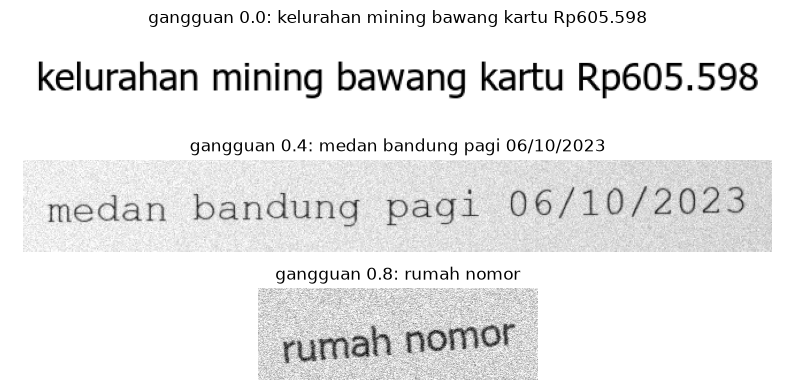

In [4]:
noise_levels = sorted(lines[NOISE_COL].unique())
fig, axes = plt.subplots(len(noise_levels), 1, figsize=(10, 4))
for ax, level in zip(axes, noise_levels):
    example = lines[lines[NOISE_COL] == level].iloc[0]
    ax.imshow(cv2.imread(f"{DATA_FOLDER}/{example[PATH_COL]}"), cmap="gray")
    ax.set_title(f"gangguan {level}: {example[TEXT_COL]}")
    ax.axis("off")
plt.tight_layout()
plt.show()

## Praproses
Perbesar 2x → haluskan bintik → ubah jadi hitam-putih. Pilih SATU baris `result`: hapus `#`
di baris yang ingin dipakai.

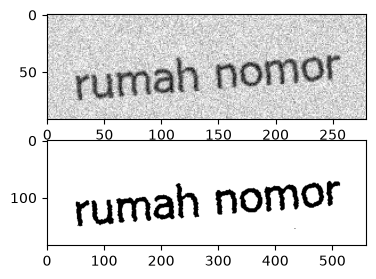

In [5]:
def preprocess(image):
    bigger = cv2.resize(image, None, fx=2, fy=2, interpolation=cv2.INTER_CUBIC)
    smooth = cv2.medianBlur(bigger, 3)
    threshold, result = cv2.threshold(smooth, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    # result = cv2.adaptiveThreshold(smooth, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    #                                cv2.THRESH_BINARY, 31, 15)
    # result = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(smooth)
    # result = smooth
    return result


example_image = cv2.imread(f"{DATA_FOLDER}/{lines.loc[2, PATH_COL]}", cv2.IMREAD_GRAYSCALE)
fig, axes = plt.subplots(2, 1, figsize=(10, 3))
axes[0].imshow(example_image, cmap="gray")
axes[1].imshow(preprocess(example_image), cmap="gray")
plt.show()

## OCR: gambar mentah vs gambar hasil praproses
Pilih SATU cara baca: hapus `#` di baris yang ingin dipakai.

In [6]:
reader = easyocr.Reader(LANGUAGES, gpu=torch.cuda.is_available(),
                        model_storage_directory=EASYOCR_FOLDER,
                        user_network_directory=EASYOCR_FOLDER,
                        download_enabled=False, verbose=False)


def read_text(image):
    pieces = reader.readtext(image, detail=0)
    # pieces = reader.readtext(image, detail=0, decoder="beamsearch")
    # pieces = reader.readtext(image, detail=0, contrast_ths=0.3, adjust_contrast=0.7)
    return " ".join(pieces)


raw_texts = []
clean_texts = []
for path in lines[PATH_COL]:
    image = cv2.imread(f"{DATA_FOLDER}/{path}", cv2.IMREAD_GRAYSCALE)
    raw_texts.append(read_text(image))
    clean_texts.append(read_text(preprocess(image)))
lines["ocr_mentah"] = raw_texts
lines["ocr_praproses"] = clean_texts

## Evaluasi CER/WER (memakai kunci, hanya untuk latihan)
Teks disamakan dulu: huruf kecil dan spasi tunggal.

In [7]:
def tidy(text):
    return " ".join(str(text).lower().split())


truth = list(lines[TEXT_COL].apply(tidy))
for column in ["ocr_mentah", "ocr_praproses"]:
    guess = list(lines[column].apply(tidy))
    print(column, "CER", round(jiwer.cer(truth, guess), 4),
          "| WER", round(jiwer.wer(truth, guess), 4))

for level in noise_levels:
    part = lines[lines[NOISE_COL] == level]
    part_truth = list(part[TEXT_COL].apply(tidy))
    raw_cer = jiwer.cer(part_truth, list(part["ocr_mentah"].apply(tidy)))
    clean_cer = jiwer.cer(part_truth, list(part["ocr_praproses"].apply(tidy)))
    print("gangguan", level, "CER mentah", round(raw_cer, 4), "| praproses", round(clean_cer, 4))

ocr_mentah CER 0.0962 | WER 0.174
ocr_praproses CER 0.0794 | WER 0.1389
gangguan 0.0 CER mentah 0.0505 | praproses 0.0413
gangguan 0.4 CER mentah 0.0517 | praproses 0.0323
gangguan 0.8 CER mentah 0.1907 | praproses 0.1685


## Kesalahan terbesar (bahan analisis presentasi)

In [8]:
line_cer = []
for true_text, guess_text in zip(truth, lines["ocr_praproses"]):
    line_cer.append(jiwer.cer(true_text, tidy(guess_text)))
lines["cer"] = line_cer
worst = lines.sort_values("cer", ascending=False)
worst[[TEXT_COL, "ocr_praproses", NOISE_COL, "cer"]].head(10)

,teks,ocr_praproses,gangguan,cer
35,putih pendidikan selamat harga 12/09/2023 Rp49...,Pi,0.8,0.960784
182,bandung kasih,kasíh bandung,0.8,0.923077
209,nomor surabaya,Ga3 3 fG9A,0.8,0.857143
175,provinsi terima mining,terima mining provinsi,0.4,0.818182
143,jalan kota pasir 30/02/2025,'iâür Kees {alu PE&,0.8,0.814815
221,jalan pos 30/09/2022,a nahe ggln9n 955,0.8,0.800000
44,ayam surabaya Rp765.177,ayam Rp76s.I77 surabaya,0.8,0.782609
233,data putih kabupaten Rp898.742,kabupaten Rp898.742 data putih,0.8,0.733333
122,gula pendidikan Rp341.867,Rp341.867 pendidikan gula,0.8,0.720000
239,publik kesehatan pagi kartu,kesehatan kartu pagi publik,0.8,0.703704


## Hasil
Saat lomba tidak ada kolom `teks` asli. Simpan hasil OCR sesuai format soal.

In [9]:
submission = pd.DataFrame()
submission["path"] = lines[PATH_COL]
submission["teks"] = lines["ocr_praproses"]
submission.to_csv("submission.csv", index=False)
submission.head()

,path,teks
0,baris/baris000.png,kelurahan mining bawang kartu Rp6o5.598
1,baris/baris001.png,medan bandung pagi 06/10/2023
2,baris/baris002.png,rumah nomor
3,baris/baris003.png,makassar provinsi bandung Rp372.123
4,baris/baris004.png,jalan kabupaten provinsi 28/08/2023
